# CS920 · Lab 1 — Can we trust a good fit?

**Duration:** 50 minutes (including initial login/Jupyter setup).  
**Today's tools:** NumPy and Matplotlib; **no GPU needed**.

## 1. Start with an energy function

Let $x\in\mathbb R$ be an input and $y\in\mathbb R$ a candidate output. Choose a **feature map** $\phi:\mathbb R\to\mathbb R^d$ and a **weight vector** $v\in\mathbb R^d$. Define

$$
\boxed{E_{v,\phi}(x,y)=\bigl(\langle v,\phi(x)\rangle-y\bigr)^2.}
$$

**Why this energy?** It is nonnegative and is minimised (to zero) precisely when

$$
y=\langle v,\phi(x)\rangle.
$$

That is, $x$ and $y$ are **compatible** when the output agrees with a *linear combination of the features* of $x$. The predictor need not be linear in the original input $x$.

For a fixed input, our **inference rule** chooses the lowest-energy output:

$$
\widehat y_{v,\phi}(x)=\arg\min_{y\in\mathbb R}E_{v,\phi}(x,y)
=\langle v,\phi(x)\rangle.
$$

**How do we learn?** Energy and loss are different concepts, though they can coincide. **For this lab, we choose the per-example training loss to be the energy itself:**

$$
\ell_{v,\phi}(x,y)=E_{v,\phi}(x,y).
$$

Given training pairs $(x_1,y_1),\ldots,(x_n,y_n)$, the average training loss is

$$
\widehat L_{\mathrm{train}}(v;\phi)
=\frac1n\sum_{i=1}^n\bigl(\langle v,\phi(x_i)\rangle-y_i\bigr)^2.
$$

**Crucial distinction for Lab 1:** We **choose $\phi$ in advance and keep it fixed** while fitting the model. We **learn only $v$**:

$$
\widehat v_{\phi}=\arg\min_{v\in\mathbb R^d}\widehat L_{\mathrm{train}}(v;\phi).
$$

We will compare several *pre-chosen* feature maps and select among them using validation data; that is not the same as learning the features from training data. **In later labs, we will learn $\phi$ as well as $v$** (for example, using a neural network to learn the representation).

**Today's question:** If we minimise training energy, does the resulting model necessarily predict well on new examples? No probabilistic interpretation is needed to define the energy above.

### Getting started (first practical only)

In a terminal on a DCS lab desktop:

```bash
module load cs920-python
mkdir -p ~/cs920/lab1
cd ~/cs920
cp -r /modules/cs920/labs/lab1 .
python -m venv venv          # once only; skip if ~/cs920/venv already exists
source venv/bin/activate
jupyter lab
```

Open `lab1/lab1.ipynb` in JupyterLab. Press **Shift+Enter** to run a code cell. If Firefox does not open automatically, copy the `http://localhost:...` URL from the terminal into Firefox.

**Time budget:** setup (10–15 min) → energy + data (6 min) → fitting (10 min) → losses (9 min) → unseen-data reveal + discussion (10 min). The optional extension can be done after class.

If setup is taking too long, ask your TA. The main goal today is to understand the experiment, not memorise Jupyter commands.


## 2. Observe the training data

We have noisy measurements of an unknown relationship between a **scalar input** $x$ and an output $y$. We also have a separate **validation set**, which we will not plot yet.

Run the next cell. There is no coding required.

Training examples: 18
Validation examples: 70


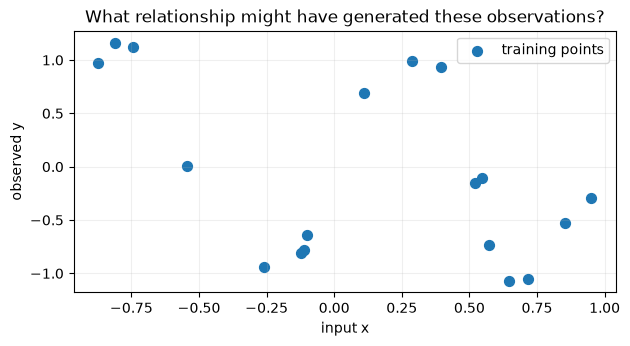

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

with np.load("lab1_data.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_val, y_val = data["x_val"], data["y_val"]

print(f"Training examples: {len(x_train)}")
print(f"Validation examples: {len(x_val)}")

# 创建画布 和 画布区域
fig, ax = plt.subplots(figsize=(7, 3.4))
# scatter() 是 Matplotlib 的散点图函数。它会将输入数组中的数据两两配对，然后将每一对数据绘制为一个点。
ax.scatter(x_train, y_train, s=50, label="training points")
# 设置x轴，y轴，标题信息
ax.set(xlabel="input x", ylabel="observed y", title="What relationship might have generated these observations?")
# 添加网格线
ax.grid(alpha=0.2)
# 显示图例
ax.legend()
plt.show()

**Stop and predict (1 minute).** Could a straight line describe these points well? Could a very flexible curve do *too* well? Discuss with the person next to you before continuing.

## 3. Choose polynomial features; learn only $v$ — coding task A

For each polynomial **degree $k$**, we *specify* the feature map

$$
\phi_k(x)=(1,x,x^2,\ldots,x^k)\in\mathbb R^{k+1}.
$$

This is the general setup from Section 1 with **feature dimension $d=k+1$** and weight vector $v=(v_0,\ldots,v_k)\in\mathbb R^{k+1}$. The energy and prediction become

$$
E_{v,\phi_k}(x,y)=\bigl(\langle v,\phi_k(x)\rangle-y\bigr)^2,
\qquad
\widehat y_{v,\phi_k}(x)=v_0+v_1x+\cdots+v_kx^k.
$$

A polynomial is therefore **linear in its features**, though generally nonlinear in $x$.

**What is fixed, and what is learnt?** When fitting degree $k$, $\phi_k$ is **fixed**. Only the coefficients $v_0,\ldots,v_k$ are estimated. Later we will compare a few *different pre-chosen* degrees using validation data.

Let $\Phi$ be the **feature matrix**, whose $i$th row is $\phi_k(x_i)$. We find $v$ by least squares, minimising the average training energy. In NumPy, `np.vander(x, N=degree + 1, increasing=True)` constructs $\Phi$.

**Fill in the two `TODO` lines** using `np.vander` and `np.linalg.lstsq`. The prediction function is provided.

In [ ]:
def fit_polynomial(x, y, degree):
    # TODO A1: construct Phi, with columns 1, x, ..., x**degree
    Phi = ...
    # TODO A2: find v minimising squared training error
    v = ...
    return v


def predict_polynomial(x, v):
    Phi = np.vander(np.asarray(x), N=len(v), increasing=True)
    return Phi @ v

**Check your code.** The following should print `Task A passed`. If it does not, return to the preceding cell.

In [ ]:
# A straight line y = 1 + 2x should be recovered exactly.
_x = np.array([-1., 0., 1., 2.])
_y = 1. + 2. * _x
_v = fit_polynomial(_x, _y, degree=1)
assert _v.shape == (2,) and np.allclose(_v, [1., 2.]), "Check task A."
print("Task A passed")

### See what the models learn from the energy

We will compare a straight line (degree 1), a moderately flexible model (degree 5), and a very flexible model (degree 12).

**Before running the plot:** which one do you expect to fit the training points most closely?

In [ ]:
x_grid = np.linspace(-1, 1, 400)
degrees_to_draw = [1, 5, 12]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for ax, degree in zip(axes, degrees_to_draw):
    v = fit_polynomial(x_train, y_train, degree)
    ax.scatter(x_train, y_train, s=24, label="training data")
    ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")
    ax.set(title=f"Degree {degree}", xlabel="x", ylim=(-2.1, 2.1))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("y")
axes[-1].legend(loc="upper center", fontsize=8)
fig.suptitle("Same training data, different model classes")
fig.tight_layout()
plt.show()
print("Note: curves that leave the vertical plot range are clipped.")

## 4. Does minimising training energy give good predictions? — coding task B

Recall: the **feature map $\phi_k$ is fixed**, we learnt $v$, and we **chose the loss to equal the energy**:

$$
\ell_{v,\phi_k}(x,y)=E_{v,\phi_k}(x,y)
=\bigl(\langle v,\phi_k(x)\rangle-y\bigr)^2.
$$

On $n$ input–output pairs, the *average loss* is the **mean squared error (MSE)**:

$$
\operatorname{MSE}=\frac1n\sum_{i=1}^n\bigl(\widehat y(x_i)-y_i\bigr)^2.
$$

We fitted $v$ to minimise this on the **training set**. We will evaluate the *same* loss on separate **validation examples**, which were not used to fit $v$.

**Complete the one-line `mse` function** using NumPy.

In [ ]:
def mse(y, y_pred):
    # TODO B: compute the mean of the squared differences
    return ...

In [ ]:
assert np.isclose(mse(np.array([1., 3.]), np.array([2., 1.])), 2.5), "Check task B."
print("Task B passed")

**Stop and predict.** If a model becomes increasingly flexible, what should happen to its *training* MSE? Must the *validation* MSE behave the same way?

Run the next cell to find out. Notice that every degree is fitted **only on the training set**.

In [ ]:
degrees = [1, 3, 5, 8, 12]
train_losses, val_losses = [], []

for degree in degrees:
    v = fit_polynomial(x_train, y_train, degree)
    train_losses.append(mse(y_train, predict_polynomial(x_train, v)))
    val_losses.append(mse(y_val, predict_polynomial(x_val, v)))

print(f"{'Degree':>6} | {'Training MSE':>12} | {'Validation MSE':>14}")
print("-" * 40)
for degree, a, b in zip(degrees, train_losses, val_losses):
    print(f"{degree:6d} | {a:12.4f} | {b:14.4f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(degrees, train_losses, "o-", label="training MSE")
ax.plot(degrees, val_losses, "s-", label="validation MSE")
ax.set(xlabel="polynomial degree", ylabel="mean squared error", title="Fitting better is not always predicting better")
ax.set_yscale("log")  # logarithmic scale: errors span a wide range
ax.set_xticks(degrees)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

**Your decision:** Which polynomial degree would you choose, based on the validation results? Compare it with the degree that minimises training MSE. Explain your reasoning in one or two sentences to your partner.

The next cell implements the validation-based choice.

In [ ]:
best_index = int(np.argmin(val_losses))
best_degree = degrees[best_index]
print(f"Smallest training MSE: degree {degrees[int(np.argmin(train_losses))]}")
print(f"Smallest validation MSE: degree {best_degree}")

## 5. Reveal the test data

A **test set** is another set of examples, withheld until the model has been selected. It is for a final assessment, **not** for repeatedly changing the selected model.

The next cell loads the hidden test examples and reveals the underlying noise-free curve. It compares our validation-selected model with the most flexible candidate. **Run it only after choosing the degree above.**

In [ ]:
with np.load("lab1_reveal.npz") as reveal:
    x_test, y_test = reveal["x_test"], reveal["y_test"]
    x_true, y_true = reveal["x_grid"], reveal["y_true_grid"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharex=True, sharey=True)
for ax, degree in zip(axes, [best_degree, 12]):
    v = fit_polynomial(x_train, y_train, degree)
    y_pred_test = predict_polynomial(x_test, v)
    ax.scatter(x_train, y_train, s=25, alpha=0.75, label="training points")
    ax.scatter(x_test, y_test, s=12, alpha=0.4, label="unseen test points")
    ax.plot(x_true, y_true, "k--", lw=1.6, label="underlying relationship")
    ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")
    ax.set(title=f"Degree {degree}; test MSE = {mse(y_test, y_pred_test):.3f}",
           xlabel="x", ylim=(-2.3, 2.3))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("y")
axes[-1].legend(fontsize=8, loc="lower center")
fig.suptitle("The reveal: training fit versus prediction on new data")
fig.tight_layout()
plt.show()
print("Some degree-12 predictions may extend well beyond the visible vertical range.")

## Exit Questions (2–3 minutes)

Jot down brief answers:

1. We kept $\phi_{12}$ fixed and learnt only $v$. The resulting model has very small **average training energy**. Why can its **validation/test energy** nevertheless be large?
2. Why shouldn't we use the test set to decide which feature map $\phi_k$ to use?
3. What is the difference between **learning $v$ for a fixed $\phi_k$** and **learning $\phi$ itself**? Which did we do today?

**Takeaway:** An energy describes compatibility, a prediction rule chooses a low-energy output, and a loss specifies the learning objective. Today we used $\ell=E$, **fixed each feature map and learnt $v$**, then used held-out data to assess generalisation. In later labs we will learn the feature representation too.

---
## Optional extension (after class)

**More data.** The degree-12 model has 13 coefficients. What happens if we give it 100 training observations instead of 18? The following cell creates a larger dataset from the same underlying relationship. Compare training and validation MSE using your existing functions. (This extension uses the test data for *no* fitting or selection.)

In [ ]:
extra_rng = np.random.default_rng(2026)
x_more = np.sort(extra_rng.uniform(-1, 1, size=100))
y_more = (np.sin(2 * np.pi * x_more)
          + 0.25 * np.cos(5 * np.pi * x_more)
          + extra_rng.normal(0, 0.17, size=len(x_more)))

for degree in [5, 12]:
    v_small = fit_polynomial(x_train, y_train, degree)
    v_large = fit_polynomial(x_more, y_more, degree)
    print(f"Degree {degree:2d}: validation MSE with 18 points = "
          f"{mse(y_val, predict_polynomial(x_val, v_small)):.4f}; "
          f"with 100 points = {mse(y_val, predict_polynomial(x_val, v_large)):.4f}")